In [17]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self,other):
        out = Value(self.data + other.data,(self,other),'+')
        return out
    def __mul__(self,other):
        out = Value(self.data * other.data,(self,other),'*')
        return out
a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = Value(10,label='c')
e = a * b; e.label = 'e'
d = e + c;d.label = 'd'
f = Value(-2.0,label='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [4]:
d._prev

{Value(data=-6.0), Value(data=10)}

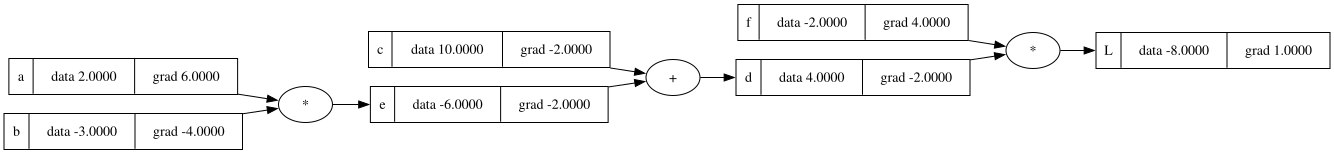

In [31]:
from graphviz import Digraph

def trace(root):
    nodes,edges = set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot = Digraph(format='svg',graph_attr={'rankdir': 'LR'})

    nodes,edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid,label="{ %s | data %.4f | grad %.4f}" % (n.label,n.data,n.grad),shape='record')
        if n._op:
            dot.node(name=uid + n._op,label=n._op)
            dot.edge(uid + n._op,uid)
    for n1,n2 in edges:
        dot.edge(str(id(n1)),str(id(n2))+ n2._op)

    return dot
draw_dot(L)

In [30]:
L.grad = 1.0
d.grad = -2.0
f.grad = 4.0
e.grad = -2.0
c.grad = -2.0
a.grad = 6.0
b.grad = -4.0

In [22]:
def lol():
    h = 0.00001

    a = Value(2.0,label='a')
    b = Value(-3.0,label='b')
    c = Value(10,label='c')
    e = a * b; e.label = 'e'
    d = e + c;d.label = 'd'
    f = Value(-2.0,label='f')
    L = d * f; L.label = 'L'
    L1 = L.data

    a = Value(2.0 + h,label='a')
    b = Value(-3.0,label='b')
    c = Value(10,label='c')
    e = a * b; e.label = 'e'
    d = e + c;d.label = 'd'
    f = Value(-2.0,label='f')
    L = d * f; L.label = 'L'
    L2 = L.data

    print((L2 - L1)/h)

lol()

6.000000000128124
